# 01 · EDA del simulador y baseline (LOG-8092)

**Qué hace:** entiende los dos escenarios públicos (5 k y 150 k tarjetas), mide el *starter* tal cual en las 7 métricas de la evaluación y
diagnostica por qué incumple los gates. Todo medido sobre el motor real. Datos: `data/` y `scenarios/public_150k/`.
Resultados del starter: `outputs/csvs/baseline_metrics.csv`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # solucion/
REPO = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import plotstyle as PS, figs
PS.apply()
CSV, FIG = ROOT / "outputs" / "csvs", ROOT / "outputs" / "figs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def show(fig):
    display(fig); plt.close(fig)

In [2]:
sh = {}
for name, p in [("5k", REPO/"data"/"shipments.csv"), ("150k", REPO/"scenarios"/"public_150k"/"shipments.csv")]:
    d = pd.read_csv(p); d["t"] = pd.to_datetime(d.available_at.str.slice(0,19))
    d["csz"] = d.groupby("delivery_cluster_id").shipment_id.transform("size")
    sh[name] = d
summ = pd.DataFrame({k: {"envíos": len(d), "clusters": d.delivery_cluster_id.nunique(),
    "% en cluster multi": round(100*(d.csz>1).mean(),1), "% metal": round(100*d.is_metal.mean(),1),
    "VIP %": round(100*(d["product"]=="VIP_BLACK").mean(),1), "REMOTA %": round(100*(d.zone=="REMOTA").mean(),1),
    "envíos/día": round(len(d)/90,0)} for k, d in sh.items()})
summ

,5k,150k
envíos,5000.0,150000.0
clusters,3839.0,115035.0
% en cluster multi,35.0,35.0
% metal,4.7,4.5
VIP %,4.7,5.0
REMOTA %,5.0,4.9
envíos/día,56.0,1667.0


## Perfil de llegadas y mezcla
La demanda sigue un perfil semanal × horario (picos 15 a 18 h, lunes y viernes, domingo ≈ ¼) y la mezcla producto × zona es casi idéntica entre zonas.
Es lo que reproduce `src/scenario_gen.py` para el Monte Carlo de escenarios.

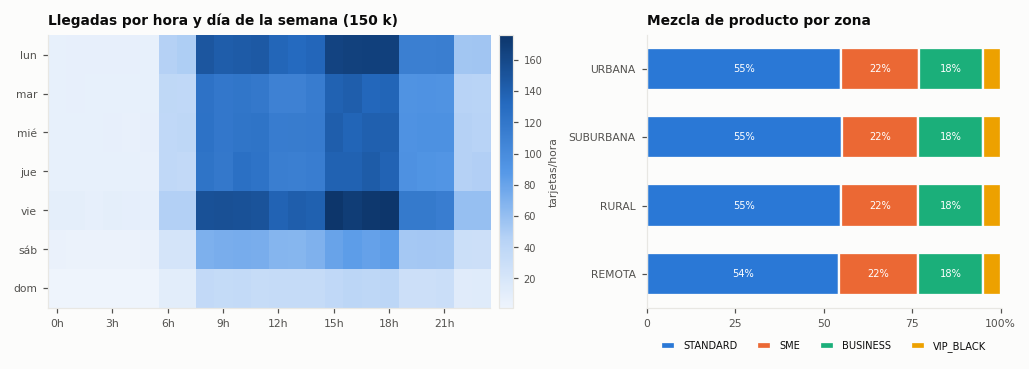

In [3]:
show(figs.eda_arrivals(sh["150k"]))

## Clusters: lo que permite (y limita) agrupar
Un lote solo admite tarjetas del mismo `delivery_cluster_id`, zona e intento. Los clusters multi-tarjeta (2 a 4) llegan **dentro de 45 min** (la ventana de retención) y
su identificador tiene una forma distinta (`CLU-E…` vs `CLU-S-…`). La política **no** hardcodea ese patrón: lo aprende en línea.

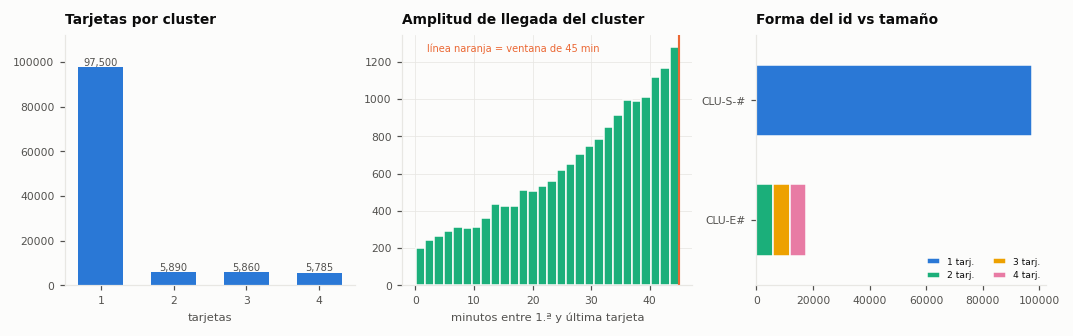

tamaño de cluster por forma de id:
csz                      1     2     3     4
delivery_cluster_id                         
CLU-E#                   0  5890  5860  5785
CLU-S-#              97500     0     0     0


In [4]:
show(figs.eda_clusters(sh["150k"]))
d = sh["150k"]; first = d.drop_duplicates("delivery_cluster_id")
print("tamaño de cluster por forma de id:")
print(pd.crosstab(first.delivery_cluster_id.str.replace(r"\d+", "#", regex=True), first.csz))

## Catálogo de carriers: coste y ETA por zona
`ida = ceil(km·60·10⁴ / (km/h · mult))`, ETA = pickup + ida; la unidad queda ocupada pickup + 2·ida.

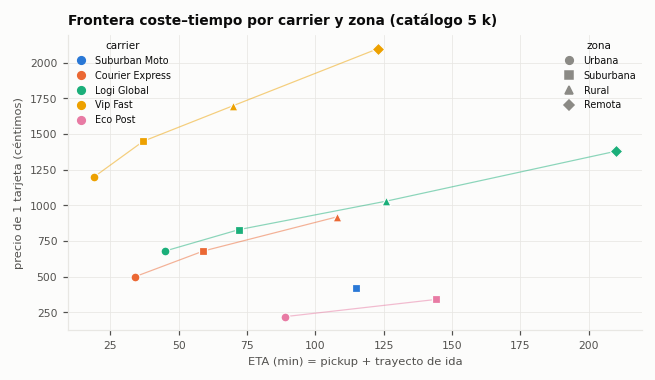

,carrier,zona,ETA_min,ocupa_min,precio_1_tarjeta,HARD_ACCESS,op_fail_bps,unidades
0,SUBURBAN_MOTO,SUBURBANA,115,185,420,False,240,6
1,COURIER_EXPRESS,URBANA,34,48,500,False,150,4
2,COURIER_EXPRESS,SUBURBANA,59,98,680,False,150,4
3,COURIER_EXPRESS,RURAL,108,196,920,False,150,4
4,LOGI_GLOBAL,URBANA,45,60,680,True,110,3
5,LOGI_GLOBAL,SUBURBANA,72,114,830,True,110,3
6,LOGI_GLOBAL,RURAL,126,222,1030,True,110,3
7,LOGI_GLOBAL,REMOTA,210,390,1380,True,110,3
8,VIP_FAST,URBANA,19,28,1200,True,50,2
9,VIP_FAST,SUBURBANA,37,64,1450,True,50,2


In [5]:
car = json.load(open(REPO/"data"/"carriers.json"))["carriers"]
dist = {"URBANA":12,"SUBURBANA":35,"RURAL":80,"REMOTA":150}
rows = []
for c in car:
    for z in c["allowed_zones"]:
        ida = -(-dist[z]*600000 // (c["speed_kmh"]*10000))
        rows.append({"carrier": c["carrier_id"], "zona": z, "ETA_min": c["pickup_minutes"]+ida, "ocupa_min": c["pickup_minutes"]+2*ida,
                     "precio_1_tarjeta": c["base_fee_cents"]+c["zone_surcharge_cents"][z], "HARD_ACCESS": "HARD_ACCESS" in c["capabilities"],
                     "op_fail_bps": c["operational_failure_bps"], "unidades": c["fleet_units"]})
cat = pd.DataFrame(rows)
show(figs.eda_catalog(cat))
cat.round(1)

## Baseline: el starter tal cual (rival a vencer)
Medido con `src/public_eval.py` (motor real, en serie, máquina quieta). CPU neta = CPU − CPU de una estrategia nula (el piso del motor).

In [6]:
bm = pd.read_csv(CSV/"baseline_metrics.csv")
bm

,policy,scenario,reps,status,admitted,delivered,returned,unresolved,hold_breaches,sla_breach_rate,rcp,cost_total,lead_mean,lead_p95,cpu_s,cpu_net_s,rss_mb,wall_s,avg_batch,failed_attempts,rejected_dispatches,upg_extra
0,noop,public_5k,3,COMPLETED,5000,0,0,5000,5000,1.00000,1.000,10000000,NaN,NaN,4.484375,0.000000,27.289062,12.041068,0.0,0,0,0
1,starter,public_5k,3,COMPLETED,5000,4983,1,16,42,0.00660,9.869,4443213,230.555,1576.0,7.687500,3.203125,29.101562,20.204649,1.0,484,9901,0
2,noop,public_150k,2,COMPLETED,150000,0,0,150000,150000,1.00000,1.000,300000000,NaN,NaN,20.562500,0.000000,27.375000,82.564654,0.0,0,0,0
3,starter,public_150k,2,COMPLETED,150000,149800,32,168,837,0.00578,9.876,138126792,225.591,1565.0,73.570312,53.007812,112.517578,235.459428,1.0,14273,207353,0


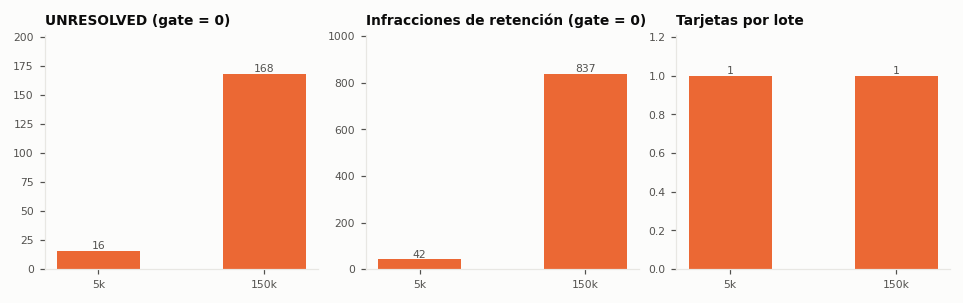

,escenario,UNRESOLVED,infracciones_retencion,despachos_rechazados,lote_medio,CAPABILITY_UNSUPPORTED,ZONE_UNSUPPORTED,coste/ref
0,5k,16,42,9901,1.0,1064,829,1.48
1,150k,168,837,207353,1.0,10060,22614,1.53


In [7]:
diag = []
for scen in ["public_5k", "public_150k"]:
    r = json.load(open(ROOT/"outputs"/"reports"/f"starter_{scen}.json"))
    diag.append({"escenario": scen.replace("public_", ""), "UNRESOLVED": r["counts"]["unresolved"], "infracciones_retencion": r["counts"]["voluntary_hold_breaches"],
                 "despachos_rechazados": r["counts"]["rejected_dispatches"], "lote_medio": r["batching"]["average_batch_size"],
                 "CAPABILITY_UNSUPPORTED": r["diagnostics"]["dispatch_rejections"]["CAPABILITY_UNSUPPORTED"],
                 "ZONE_UNSUPPORTED": r["diagnostics"]["dispatch_rejections"]["ZONE_UNSUPPORTED"],
                 "coste/ref": round(r["costs"]["total_cents"]/r["costs"]["reference_budget_cents"],2)})
diag = pd.DataFrame(diag); show(figs.baseline_diag(diag)); diag

### Diagnóstico de los fallos del starter (verificado en el código y en el reporte)
1. **Round-robin de 1 tarjeta por lote** → `average_batch_size = 1,0`: nunca aprovecha que el linehaul se cobra por lote (coste ≈ +46 % sobre la referencia).
2. **Reintento al mismo carrier tras `INACCESSIBLE_ROUTE`**: `last_carrier_by_shipment` fija el carrier original aunque no tenga `HARD_ACCESS`
   → `CAPABILITY_UNSUPPORTED` repetido y, al final, **UNRESOLVED** (incumple el gate).
3. **Chequeo de zona por subcadena** (`shipment.zone in "|".join(zonas)`): `"URBANA" in "SUBURBANA"` es verdadero → intentos a carriers que no cubren la zona (`ZONE_UNSUPPORTED`).
4. **Retención involuntaria**: examina cada tarjeta una vez por tick con un carrier fijo; si no cabe, la deja pendiente aunque haya otro carrier libre → **infracciones de retención** (gate).
5. **`all_historical_records`** guarda todos los envíos (memoria ∝ nº de tarjetas: ≈ 113 MiB en 150 k vs ≈ 28 MiB de piso).